# BHSM Blackhole Tracker: a primary target and one moving object

First inspect the **source-pinned primary investigation program**,
including all eight published Gaia18ajz alternatives, its known-BH
reference, a non-BH comparison and the publication hold. Then run a
**SYNTHETIC angular-track demonstration** through validation, a
covariance-aware fit, residual plots, export and replay.

Ordinary gravitational geometry is usable within the BHSM surface
interpretation. The same Einstein/GHY exterior response is counted
once. An angular track can locate a configuration in its supplied
frame before a mass is known; a line alone does not establish the
gravitational origin, a microscopic surface shape or a BH identity.

The default walkthrough reads **no observations**, makes no network
request and performs no native-data fit. Its six angular positions
and full covariance are explicitly invented. Optional measured-data
use requires a separately chosen new JSON file and a second explicit
fit switch near the end. Catalog source directions from the spectrum
are not substituted for foreground-lens measurements.

Install the matching wheel and run this notebook in a working
directory you own. It creates a fresh export directory below
`user_runs/`; existing analyses are never overwritten. Source and
citation: [formal BHSM reviewer repository](https://github.com/ncarberry64/Berger-Hopf-Standard-Model).


In [1]:
import hashlib
import json
from pathlib import Path
from tempfile import mkdtemp

import numpy as np
import matplotlib.pyplot as plt
import bhtracker
from bhtracker.target_program import target_program
from bhtracker.interpretation import surface_geometry_interpretation
from bhtracker.skytrack import (
    synthetic_example, validate_skytrack, fit_skytrack,
    export_skytrack, replay_skytrack,
)

assert bhtracker.__version__ == '0.2.0rc6', "Install the wheel matching this notebook."
program = target_program()  # Refuses altered source-pinned program bytes.
primary = program["primary_investigation_target"]
assert primary["investigation_category"] == "Potential black hole"
assert program["publication_gate"]["ready"] is False
assert all(value is None for value in primary["engine_measurements"].values())
print("Installed product:", bhtracker.__version__)
print("Primary investigation target:", primary["event_id"])
print("Evidence program SHA-256:", program["program_sha256"])
print("Literature history:", primary["novelty_status"])
print("Primary source:", primary["source"]["url"])
print("Engine quantities:", primary["engine_measurements"])


Installed product: 0.2.0rc6
Primary investigation target: Gaia18ajz
Evidence program SHA-256: 175c4b11279bb0397b48eb76d38b556b30eb246ef005bb1cb1cfab510dd32f48
Literature history: PREVIOUSLY_PUBLISHED_CANDIDATE_NOT_A_NEW_ENGINE_DISCOVERY
Primary source: https://arxiv.org/html/2403.09006v3
Engine quantities: {'mass_msun': None, 'lens_distance_pc': None, 'theta_E_mas': None, 'absolute_lens_motion': None, 'accepted_mass_interval_msun': None}


## Inspect the competing Gaia18ajz interpretations

These values are **published prior-conditional posterior medians**,
not tracker mass measurements. Near/far weights are normalized
within one photometric mode and one mass prior. They are not BH
probabilities or weights to pool across the four scenarios. Keep
the lower-mass alternatives and the primary paper's uncertainties,
source-astrometry and photometric-error qualifications visible.
The full program and its primary citation remain in the export.


In [2]:
alternatives = primary["literature_alternatives"]
assert len(alternatives) == 8
print("mode | mass prior | branch | within-scenario weight | published median [solar mass]")
for alternative in alternatives:
    print(" | ".join(str(alternative[key]) for key in (
        "photometric_mode", "mass_prior", "branch",
        "published_branch_weight", "published_mass_posterior_median_msun",
    )))
for mode in ("GO-", "GO+"):
    for prior in ("StellarIMF", "DarkIMF"):
        scenario = [row for row in alternatives
                    if row["photometric_mode"] == mode and row["mass_prior"] == prior]
        assert {row["branch"] for row in scenario} == {"Near", "Far"}
        assert abs(sum(row["published_branch_weight"] for row in scenario) - 1.0) < 1e-12
print("What could change the interpretation:")
for reason in primary["evidence_against_or_unresolved"]:
    print(" -", reason)


mode | mass prior | branch | within-scenario weight | published median [solar mass]
GO- | StellarIMF | Near | 0.47 | 7.2
GO- | StellarIMF | Far | 0.53 | 0.94
GO- | DarkIMF | Near | 0.96 | 11.1
GO- | DarkIMF | Far | 0.04 | 1.11
GO+ | StellarIMF | Near | 0.94 | 2.8
GO+ | StellarIMF | Far | 0.06 | 0.4
GO+ | DarkIMF | Near | 0.999 | 4.9
GO+ | DarkIMF | Far | 0.001 | 0.59
What could change the interpretation:
 - Stellar and remnant priors retain different near/far and lower-mass alternatives.
 - Gaia source astrometry has elevated RUWE; source distance and proper-motion assumptions matter.
 - Published Gaia errors were estimated; photometric errors were rescaled and a blend prior was used.
 - Independent adequate native-data recovery and direct angular-scale constraints are not established by this release.


In [3]:
known = program["known_black_hole_validation_benchmark"]
control = program["non_black_hole_comparison"]
assert known["independent_engine_recovery_accepted"] is False
assert control["independently_recovered_by_this_engine"] is False
print(json.dumps({
    "published_positive_BH_reference": known,
    "published_non_BH_comparison": control,
    "publication_gate": program["publication_gate"],
    "BHSM_interpretation": program["bhsm_interpretation"],
}, indent=2))
common_geometry = surface_geometry_interpretation()
print("Common BHSM surface-geometry contract:")
print(json.dumps(common_geometry, indent=2))


{
  "published_positive_BH_reference": {
    "event_id": "OGLE-2011-BLG-0462",
    "aliases": [
      "MOA-2011-BLG-191",
      "OB110462"
    ],
    "role": "PUBLISHED_POSITIVE_REFERENCE_NOT_PRIMARY_NEW_CANDIDATE",
    "source_url": "https://doi.org/10.3847/1538-4357/adbe6e",
    "independent_engine_recovery_accepted": false,
    "engine_status": "RETAINED_JOINT_MODEL_NOISE_FAILURES_NO_ACCEPTED_MASS"
  },
  "published_non_BH_comparison": {
    "event_id": "OGLE-2007-BLG-224",
    "role": "PUBLISHED_BROWN_DWARF_COUNTEREXAMPLE",
    "source_url": "https://arxiv.org/abs/0904.0249v2",
    "followup_source_url": "https://arxiv.org/abs/2011.06013",
    "literature_mass_msun": 0.056,
    "literature_mass_sigma_msun": 0.004,
    "literature_lens_distance_pc": 525,
    "literature_transverse_velocity_km_s": 113,
    "independently_recovered_by_this_engine": false
  },
  "publication_gate": {
    "ready": false,
    "primary_research_target_designated": true,
    "independent_candidate_evidence

## SYNTHETIC angular positions of one invented object

This demonstration concerns actual *input roles*, not an observed
black hole: positions are declared foreground-lens tangent-plane
positions in an invented frame. Every row refers to the same
synthetic identity. Its source hashes label constructed fixtures.

We supply one full $2N\times2N$ covariance, including invented
cross-epoch correlations. It is never estimated from these residuals
or rescaled to make a desired answer pass. Gaussian supplied-noise
and frame/parallax declarations are part of the conditional model.
All coordinate, epoch, covariance and source-row declarations remain
in the exact input JSON, including an unused `null` annotation.


In [4]:
document = synthetic_example()
assert document["metadata"]["kind"] == "synthetic"
assert document["metadata"]["known_black_hole"] is False
n = len(document["rows"])
full_covariance = np.zeros((2 * n, 2 * n))
for index, row in enumerate(document["rows"]):
    full_covariance[2*index:2*index+2, 2*index:2*index+2] = row.pop("covariance_mas2")
invented_common_mode = np.linspace(-1.0, 1.0, 2 * n)
full_covariance += 0.003 * np.outer(invented_common_mode, invented_common_mode)
document["full_covariance_mas2"] = full_covariance.tolist()
document["noise"]["covariance_kind"] = "FULL_2N"
document["noise"]["cross_epoch_independence"] = None
document["noise"]["covariance_source"] = (
    "Notebook 06 INVENTED full covariance: fixture blocks plus a constructed common mode; no measured calibration."
)
document["metadata"]["notebook_annotation"] = {
    "label": "SYNTHETIC angular control — not a known or discovered BH",
    "unavailable_external_information": None,
}
# Deliberately retain UTF-8, indentation and CRLF as original input text.
original_text = json.dumps(document, indent=3, ensure_ascii=False, allow_nan=False).replace("\n", "\r\n") + "\r\n"
original_bytes = original_text.encode("utf-8")
original_sha256 = hashlib.sha256(original_bytes).hexdigest()
admission = validate_skytrack(original_text)
assert admission["valid"] and admission["rows"] == 6
assert admission["input_utf8_sha256"] == original_sha256
assert admission["covariance_kind"] == "FULL_2N"
print("SYNTHETIC input admission:", json.dumps(admission, indent=2))


SYNTHETIC input admission: {
  "schema": "bhtracker.measured_lens_skytrack_observations.v1",
  "valid": true,
  "lens_id": "SYNTHETIC-LENS",
  "rows": 6,
  "unique_epochs": 6,
  "rank": 4,
  "goodness_of_fit_testable": true,
  "input_utf8_sha256": "f6760859e301193ff33d22691b25decc051cfc7a6dc5eb26a768e9340d35a37b",
  "frame": {
    "name": "SYNTHETIC-INERTIAL-TANGENT",
    "kind": "INERTIAL_TANGENT_PLANE",
    "axes": [
      "east",
      "north"
    ],
    "angular_unit": "mas",
    "reference_origin": "Constructed tangent origin; no sky position assigned.",
    "absolute_frame": false,
    "calibration_source": "Invented control, no measured calibration.",
    "parallax_treatment": "NOT_MODELED_CONDITIONAL_RECTILINEAR",
    "parallax_source": "No annual parallax in the constructed signal."
  },
  "time": {
    "native_unit": "day",
    "numeric_origin": 2450000.0,
    "convention": "native_time + numeric_origin, JD_TDB for constructed control",
    "scale": "TDB",
    "source": "Inve

## Fit motion in the supplied frame; inspect covariance and diagnostics

This is a centered generalized least-squares angular-track fit.
`significance_alpha=None` requests statistics without turning a
chosen threshold into a detection label. The parameter covariance
retains correlations among both position components and both motion
components. The observed full covariance remains unchanged.

No distance, physical transverse speed, mass, horizon or microscopic
interface shape follows from this angular line. An accepted linear
trend would also require credible source/lens association, angular
calibration, frame, clock, parallax and noise assumptions.


In [5]:
result = fit_skytrack(original_text, reference_native_time=6000.0, significance_alpha=None)
assert result["dataset_input_json"] == original_text
assert result["input_utf8_sha256"] == original_sha256
assert result["status"] == "RECTILINEAR_FIT_STATISTICS_ONLY"
assert all(value is None for value in result["unavailable"].values())
assert result["dataset_input"]["full_covariance_mas2"] == document["full_covariance_mas2"]
print("SYNTHETIC fit status:", result["status"])
print("Parameter order:", result["parameter_order"])
print("Parameters in the supplied frame:", result["parameters"])
print("Full parameter covariance:", np.asarray(result["parameter_covariance"]), sep="\n")
print("Conditional diagnostics:", json.dumps(result["diagnostics"], indent=2))
print("Unavailable physical quantities:", result["unavailable"])


SYNTHETIC fit status: RECTILINEAR_FIT_STATISTICS_ONLY
Parameter order: ['east_ref_mas', 'north_ref_mas', 'mu_east_mas_per_Julian_year', 'mu_north_mas_per_Julian_year']
Parameters in the supplied frame: {'position_mas': [11.99675526847949, -7.9999871289444116], 'angular_motion_mas_per_Julian_year': [79.99135654774312, -29.999843617511974]}
Full parameter covariance:
[[ 6.75604106e-03  1.65644522e-03 -2.51937753e-04 -1.27996418e-04]
 [ 1.65644522e-03  1.50839153e-02 -1.16101581e-05 -3.42120383e-04]
 [-2.51937753e-04 -1.16101581e-05  9.29974189e-04  3.35055784e-04]
 [-1.27996418e-04 -3.42120383e-04  3.35055784e-04  1.92150486e-03]]
Conditional diagnostics: {
  "chi_square": 4.5140774096879035,
  "degrees_of_freedom": 8,
  "unique_epochs": 6,
  "goodness_of_fit_testable": true,
  "chi_square_upper_probability": 0.8080230592734852,
  "chi_square_lower_probability": 0.1919769407265149,
  "chi_square_two_sided_probability": 0.3839538814530298,
  "stationary_null_delta_chi_square": 8801658.308

## Plot the SYNTHETIC track and all residuals

The points below are invented lens positions, unlike the catalog
source markers in the evidence spectrum. Error bars display native
marginal standard deviations only; the fit used the full covariance.
Every input epoch remains in both residual panels. The line joins
the saved predictions of this rectilinear demonstration.


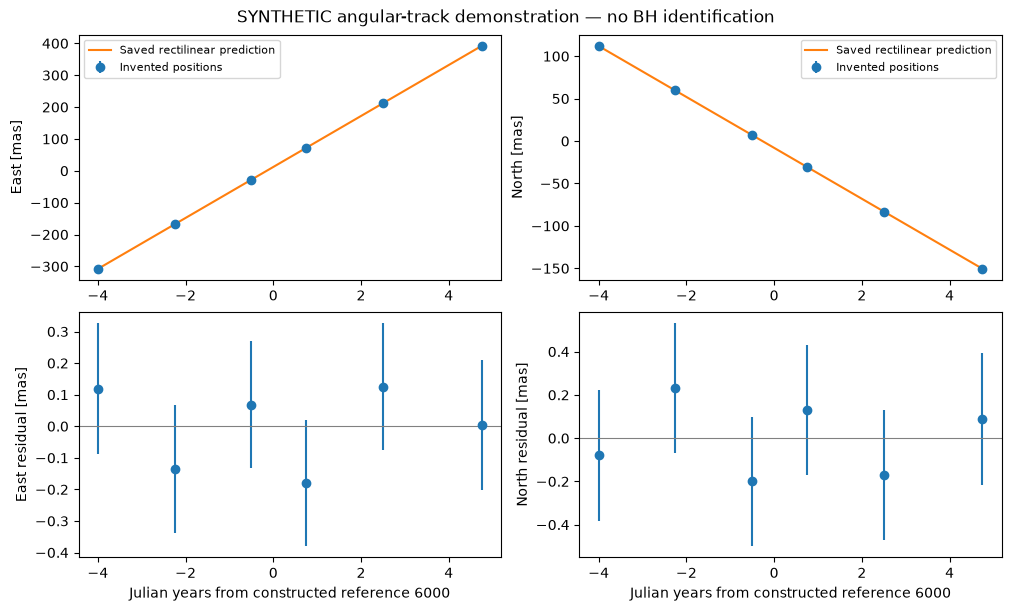

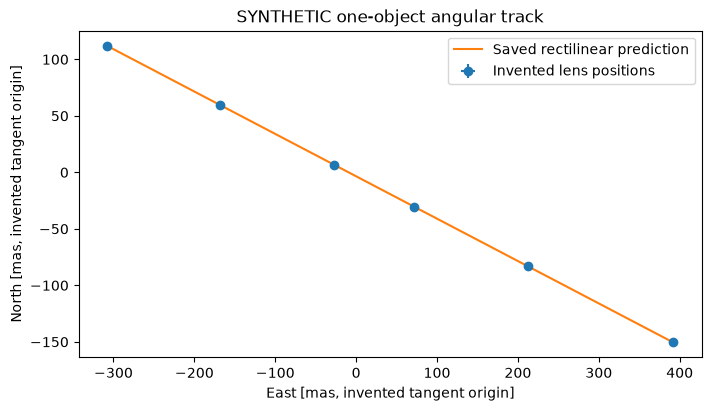

In [6]:
native_time = np.asarray([row["native_time"] for row in document["rows"]])
relative_years = (native_time - 6000.0) / 365.25
observed = np.asarray([row["position_mas"] for row in document["rows"]])
predicted = np.asarray(result["predictions_mas"])
residual = np.asarray(result["residuals_mas"])
marginal_sigma = np.sqrt(np.diag(np.asarray(document["full_covariance_mas2"]))).reshape(n, 2)
order = np.argsort(native_time, kind="stable")
figure, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
for axis, name in enumerate(("East", "North")):
    axes[0, axis].errorbar(relative_years, observed[:, axis], yerr=marginal_sigma[:, axis], fmt="o", label="Invented positions")
    axes[0, axis].plot(relative_years[order], predicted[order, axis], label="Saved rectilinear prediction")
    axes[0, axis].set(ylabel=name + " [mas]")
    axes[0, axis].legend(fontsize=8)
    axes[1, axis].errorbar(relative_years, residual[:, axis], yerr=marginal_sigma[:, axis], fmt="o")
    axes[1, axis].axhline(0.0, color="0.5", linewidth=0.8)
    axes[1, axis].set(xlabel="Julian years from constructed reference 6000", ylabel=name + " residual [mas]")
figure.suptitle("SYNTHETIC angular-track demonstration — no BH identification")
plt.show()
sky_figure, sky_axis = plt.subplots(figsize=(7, 4), layout="constrained")
sky_axis.errorbar(observed[:, 0], observed[:, 1], xerr=marginal_sigma[:, 0], yerr=marginal_sigma[:, 1], fmt="o", label="Invented lens positions")
sky_axis.plot(predicted[order, 0], predicted[order, 1], label="Saved rectilinear prediction")
sky_axis.set(xlabel="East [mas, invented tangent origin]", ylabel="North [mas, invented tangent origin]", title="SYNTHETIC one-object angular track")
sky_axis.legend()
plt.show()


## Export, read back and replay

The exported `dataset.json` must preserve the exact original UTF-8
text, including CRLF and unknown `null` values. Numerical replay
checks the method source, retained input and saved result under its
declared engineering comparison budget; it does not certify the
association, noise calibration or physical BH identity. A hash is a
consistency check, not an authenticity or discovery certificate.

Each run creates a unique directory. The source-pinned target
program, conditional result, replay checks and SYNTHETIC plot cards
remain available there for inspection.


In [7]:
output_parent = Path.cwd() / "user_runs"
output_parent.mkdir(exist_ok=True)
run_directory = Path(mkdtemp(prefix="moving_lens06_", dir=output_parent))
bundle_directory = run_directory / "synthetic_angular_track"
export_check = export_skytrack(result, bundle_directory)
assert export_check["passed"]
exported_input = (bundle_directory / "dataset.json").read_bytes()
assert exported_input == original_bytes
saved_result = json.loads((bundle_directory / "result.json").read_bytes())
replay = replay_skytrack(saved_result)
assert replay["passed"]
assert saved_result["dataset_input_json"].encode("utf-8") == original_bytes
assert all(value is None for value in saved_result["unavailable"].values())
assert saved_result["dataset_input"]["metadata"]["notebook_annotation"]["unavailable_external_information"] is None
with (run_directory / "primary_target_program.json").open("x", encoding="utf-8", newline="\n") as stream:
    json.dump(program, stream, indent=2, ensure_ascii=False, allow_nan=False)
    stream.write("\n")
figure.savefig(run_directory / "SYNTHETIC_track_and_residuals.png", dpi=150)
sky_figure.savefig(run_directory / "SYNTHETIC_angular_track.png", dpi=150)
print("Fresh export:", run_directory.resolve())
print("Exact original input SHA-256:", original_sha256)
print("Retained source rows:", saved_result["source_row_ids"])
print("Replay:", json.dumps(replay, indent=2))
print("Publication readiness remains:", program["publication_gate"]["ready"])


Fresh export: C:\Users\carbe\OneDrive\Documents\CODEX\outputs\bhsm_real_data_corrections_20261022\expanded_dataset_search_20261023\notebook06_final_installed_execution_v2\fresh_kernel_workdir\user_runs\moving_lens06_2txn9k5_
Exact original input SHA-256: f6760859e301193ff33d22691b25decc051cfc7a6dc5eb26a768e9340d35a37b
Retained source rows: ['synthetic:1', 'synthetic:2', 'synthetic:3', 'synthetic:4', 'synthetic:5', 'synthetic:6']
Replay: {
  "schema": "bhtracker.measured_lens_skytrack_replay.v1",
  "passed": true,
  "checks": {
    "status": true,
    "fit_configuration": true,
    "reference_epoch": true,
    "parameter_order": true,
    "source_row_ids": true,
    "unavailable": true,
    "qualifications": true,
    "surface_geometry_interpretation": true,
    "parameters": true,
    "numerical_fit": true,
    "predictions_mas": true,
    "residuals_mas": true,
    "whitened_residuals": true,
    "parameter_covariance": true,
    "standard_errors": true,
    "diagnostic_exact_fields":

## Optional new measured input — disabled by default

To examine observations, explicitly select a **new** JSON dataset
with measured foreground-lens angular positions or lens positions
inferred by an independently identified joint model. Supply source
row identities, native clocks, angular frame, association evidence
and the covariance route. Source/event RA and Dec or raw unresolved
source centroids do not meet this input contract.

Selecting a path performs declaration/numerical validation only.
Starting a new conditional fit needs the separate switch. The new
result stays separate from the synthetic demonstration and all
historical frozen results. No observed input is selected here.


In [8]:
REAL_TRACK_JSON = None
RUN_NEW_REAL_TRACK_FIT = False
real_result = None
if REAL_TRACK_JSON is None:
    if RUN_NEW_REAL_TRACK_FIT:
        raise ValueError("Choose a new measured-data JSON file explicitly before requesting a fit.")
    print("No observed dataset selected; no native-data validation or fit requested.")
else:
    real_original_bytes = Path(REAL_TRACK_JSON).read_bytes()
    real_original_text = real_original_bytes.decode("utf-8")
    print(json.dumps(validate_skytrack(real_original_text), indent=2))
    if RUN_NEW_REAL_TRACK_FIT:
        real_result = fit_skytrack(real_original_text, significance_alpha=None)
        print("New conditional angular result:", real_result["status"])
        print("Physical quantities still unavailable:", real_result["unavailable"])
    else:
        print("Input declarations validated; no new fit requested.")


No observed dataset selected; no native-data validation or fit requested.


The completed demonstration establishes a usable, covariance-aware
angular workflow and a source-pinned investigation programme. It
establishes no real shared-lens sequence, accepted known-BH recovery
or new BH interpretation. The primary target remains a previously
published candidate, and scientific publication remains held for
candidate evidence and recovery validation. The BHSM interpretation
connects supported gravitational geometry to surface topography
while leaving microscopic configuration and BH identity to their
own evidence.
